In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [3]:
columns = [
    'age', 'sex', 'cp', 'trestbps', 'chol',
    'fbs', 'restecg', 'thalach', 'exang',
    'oldpeak', 'slope', 'ca', 'thal', 'num'
]

# Завантаження даних
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

df = pd.read_csv(url, names=columns)

df = df.apply(pd.to_numeric, errors='coerce')
# Видалення рядків із пропущеними значеннями
df = df.dropna()
df['risk'] = (df['num']>0).astype(int)
df = df.drop(columns=['num'])

# Відокремлення ознак та цільової змінної
X = df.drop(columns=['risk'])
y = df['risk']

# Розділення даних
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [4]:
X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)

y_train = torch.tensor(
    y_train.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

y_test = torch.tensor(
    y_test.to_numpy(),
    dtype=torch.float32
).reshape(-1, 1)

In [5]:
input_size = X_train.shape[1]

model = nn.Sequential(
    nn.Linear(input_size, 16),
    nn.ReLU(),

    nn.Linear(16, 8),
    nn.ReLU(),

    nn.Linear(8, 1),
    nn.Sigmoid()
)

print(model)

Sequential(
  (0): Linear(in_features=13, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=8, bias=True)
  (3): ReLU()
  (4): Linear(in_features=8, out_features=1, bias=True)
  (5): Sigmoid()
)


In [6]:
train_dataset = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

train_losses = []
train_accuracies = []

for epoch in range(epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for inputs, labels in train_loader:

        optimizer.zero_grad()

        outputs = model(inputs)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = (outputs >= 0.5).float()

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / len(train_loader)
    epoch_accuracy = correct / total

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {epoch_loss:.4f}, "
            f"Accuracy: {epoch_accuracy:.4f}"
        )

Epoch [10/100], Loss: 0.6435, Accuracy: 0.8186
Epoch [20/100], Loss: 0.4703, Accuracy: 0.8397
Epoch [30/100], Loss: 0.3849, Accuracy: 0.8481
Epoch [40/100], Loss: 0.3339, Accuracy: 0.8608
Epoch [50/100], Loss: 0.3177, Accuracy: 0.8608
Epoch [60/100], Loss: 0.3070, Accuracy: 0.8692
Epoch [70/100], Loss: 0.2798, Accuracy: 0.8903
Epoch [80/100], Loss: 0.2714, Accuracy: 0.8903
Epoch [90/100], Loss: 0.2430, Accuracy: 0.9030
Epoch [100/100], Loss: 0.2531, Accuracy: 0.9072


In [7]:

model.eval()

with torch.no_grad():

    test_outputs = model(X_test)

    test_predictions = (test_outputs >= 0.5).float()

accuracy = accuracy_score(
    y_test.numpy(),
    test_predictions.numpy()
)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

print(classification_report(
    y_test.numpy(),
    test_predictions.numpy()
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test.numpy(),
    test_predictions.numpy()
))

Test Accuracy: 83.33%
              precision    recall  f1-score   support

         0.0       0.84      0.84      0.84        32
         1.0       0.82      0.82      0.82        28

    accuracy                           0.83        60
   macro avg       0.83      0.83      0.83        60
weighted avg       0.83      0.83      0.83        60

Confusion Matrix:
[[27  5]
 [ 5 23]]


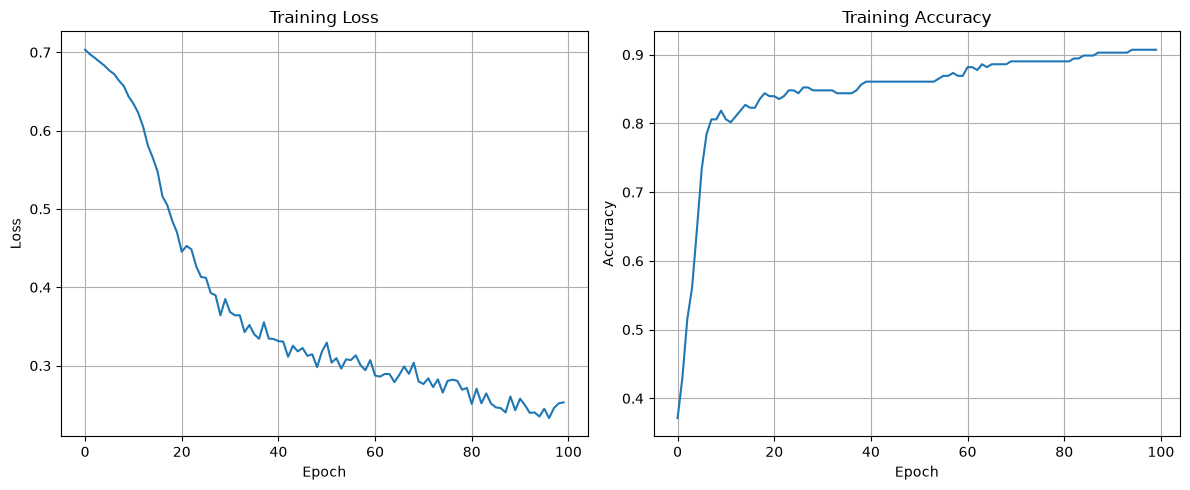

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses)
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid()

plt.subplot(1, 2, 2)
plt.plot(train_accuracies)
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid()

plt.tight_layout()
plt.savefig("mlp_training.png", dpi=300)
plt.show()